# Kvasir-Capsule VCE Triage EDA

Exploratory data analysis on the preprocessed manifest. Covers:

1. Class distribution per subclass per fold
2. Binary aggregate: Normal vs Suspicious per fold
3. Intra-video duplication estimate (frame burst analysis)
4. Exclusion impact summary (derived from labelled_images/ and EXCLUDED_CLASSES config)
5. Bounding-box normalized area distribution
6. Preprocessing verification (sample images from NPZ shards)
7. Visual ambiguity grid (Normal mucosa vs Erythema vs Erosion)
8. Per-fold normalization statistics
9. Bounding-box position verification
10. Augmented dataset visualizations (sample grid + per-transform breakdown)

Requires `scripts/preprocess.py` to have run first so that
`outputs/preprocessed/manifest.csv` exists.

In [ ]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# resolve project root so we can import from src/
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if (NOTEBOOK_DIR.parent / 'pyproject.toml').exists() else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from kvasir_triage.data.labels import DIR_NAME_MAP, EXCLUDED_CLASSES, BINARY_LABEL, NORMAL_CLASSES
from kvasir_triage.data.splits import infer_video_id
from kvasir_triage.paths import corner_mask_path, eda_root, norm_stats_path, outputs_root, preprocessed_root

EDA_DIR = eda_root()
EDA_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Load manifest - try new location first, fall back to legacy
MANIFEST = preprocessed_root() / 'manifest.csv'
if not MANIFEST.exists():
    raise FileNotFoundError(
        'manifest.csv not found. Run scripts/preprocess.py first.'
    )

df = pd.read_csv(MANIFEST)
print(f'Manifest: {MANIFEST}')
print(f'Total rows: {len(df)}')
print(f'Folds: {sorted(df["fold"].unique())}')
print(f'Subclasses ({df["subclass"].nunique()}): {sorted(df["subclass"].unique())}')

Manifest: D:\Git\AAIB\outputs\preprocessed\manifest.csv
Total rows: 47161
Folds: [np.int64(0), np.int64(1), np.int64(2)]
Subclasses (11): ['Angiectasia', 'Blood - fresh', 'Erosion', 'Erythema', 'Foreign body', 'Ileocecal valve', 'Lymphangiectasia', 'Normal clean mucosa', 'Pylorus', 'Reduced mucosal view', 'Ulcer']


In [3]:
# Helper: resolve shard absolute path from either manifest format
def shard_abs(row: pd.Series) -> Path:
    if 'shard_rel_path' in row.index and pd.notna(row['shard_rel_path']):
        return (outputs_root() / row['shard_rel_path']).resolve()
    if 'shard_path' in row.index and pd.notna(row['shard_path']):
        return Path(row['shard_path'])
    raise KeyError('No shard path column found in manifest.')


def load_image_from_row(row: pd.Series) -> np.ndarray | None:
    try:
        path = shard_abs(row)
        data = np.load(str(path), allow_pickle=False)
        return data["images"][int(row["local_idx"])]
    except Exception as e:
        warnings.warn(f"Could not load shard: {e}")
        return None


## 1. Class distribution per subclass per fold

fold,0,1,2
subclass,,,
Normal clean mucosa,10556,14755,9027
Ileocecal valve,2408,902,879
Reduced mucosal view,762,1974,170
Angiectasia,760,67,39
Pylorus,578,519,432
Ulcer,272,582,0
Lymphangiectasia,224,368,0
Foreign body,203,0,573
Erosion,81,377,48


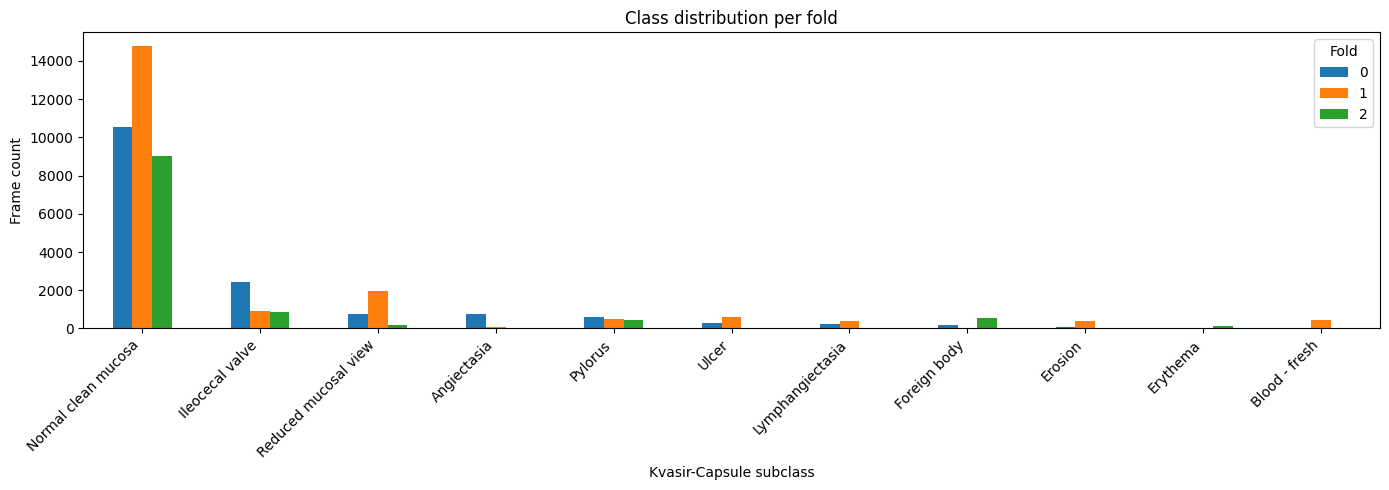

In [17]:
class_counts = (
    df.groupby(['subclass', 'fold'])
    .size()
    .unstack(fill_value=0)
    .sort_values(0, ascending=False)
)
display(class_counts)

ax = class_counts.plot(kind='bar', figsize=(14, 5))
ax.set_title('Class distribution per fold')
ax.set_xlabel('Kvasir-Capsule subclass')
ax.set_ylabel('Frame count')
ax.legend(title='Fold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(EDA_DIR / 'class_distribution_by_fold.png', dpi=200)
plt.show()

eda_summary = {'class_counts_by_fold': class_counts.to_dict()}

## 1b. Split balance check

Verifies that every subclass is represented in every fold and that CV folds (0 and 1) each hold ~40 % of that subclass's frames while the test fold (2) holds ~20 %.

Subclass frame counts per fold:


fold,CV fold 0,CV fold 1,Test
subclass,,,
Angiectasia,760,67,39
Blood - fresh,22,424,0
Erosion,81,377,48
Erythema,36,0,123
Foreign body,203,0,573
Ileocecal valve,2408,902,879
Lymphangiectasia,224,368,0
Normal clean mucosa,10556,14755,9027
Pylorus,578,519,432



Subclass proportions per fold (%):


fold,CV fold 0,CV fold 1,Test
subclass,,,
Angiectasia,87.8,7.7,4.5
Blood - fresh,4.9,95.1,0.0
Erosion,16.0,74.5,9.5
Erythema,22.6,0.0,77.4
Foreign body,26.2,0.0,73.8
Ileocecal valve,57.5,21.5,21.0
Lymphangiectasia,37.8,62.2,0.0
Normal clean mucosa,30.7,43.0,26.3
Pylorus,37.8,33.9,28.3



⚠ MISSING subclasses:
  Blood - fresh: absent from ['Test']
  Erythema: absent from ['CV fold 1']
  Foreign body: absent from ['CV fold 1']
  Lymphangiectasia: absent from ['Test']
  Ulcer: absent from ['Test']

CV fold imbalance (std/mean of proportions, lower → more even):
  Erythema                        1.41  ████████████████████████████
  Foreign body                    1.41  ████████████████████████████
  Blood - fresh                   1.27  █████████████████████████
  Angiectasia                     1.19  ███████████████████████
  Erosion                         0.91  ██████████████████
  Ileocecal valve                 0.64  ████████████
  Reduced mucosal view            0.63  ████████████
  Ulcer                           0.51  ██████████
  Lymphangiectasia                0.34  ██████
  Normal clean mucosa             0.23  ████
  Pylorus                         0.08  █


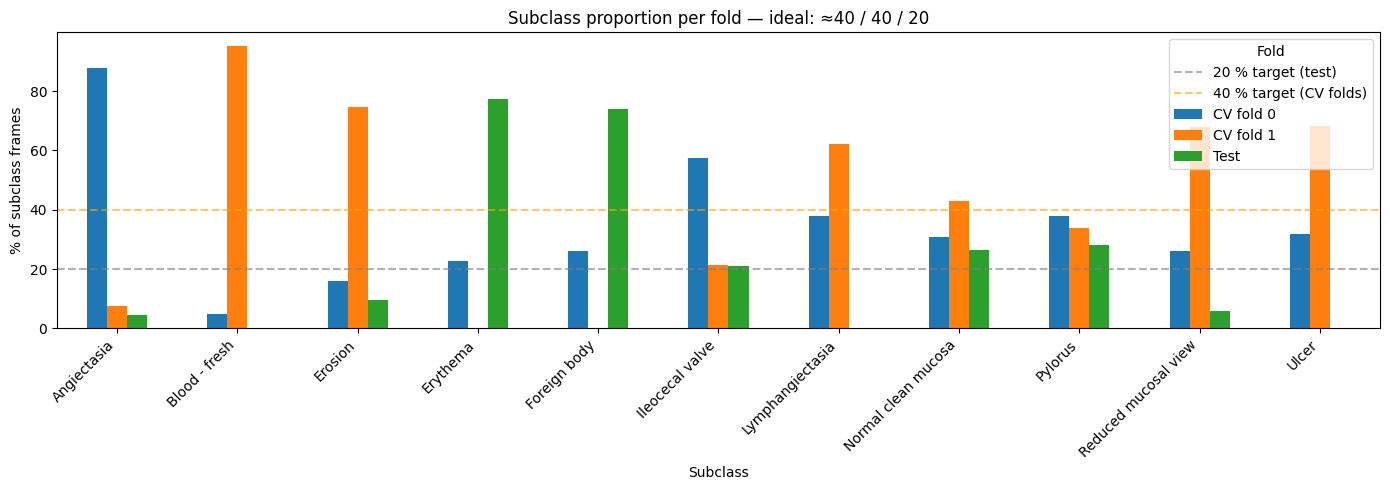

In [18]:
fold_labels = {0: 'CV fold 0', 1: 'CV fold 1', 2: 'Test'}

# Raw counts and proportions
balance = (
    df.groupby(['subclass', 'fold'])
    .size()
    .unstack(fill_value=0)
    .rename(columns=fold_labels)
)
balance_pct = balance.div(balance.sum(axis=1), axis=0).mul(100)

print('Subclass frame counts per fold:')
display(balance)
print('\nSubclass proportions per fold (%):')
display(balance_pct.round(1))

# Flag missing subclasses (zero frames in any fold)
missing = balance == 0
if missing.any().any():
    print('\n⚠ MISSING subclasses:')
    for sc in missing.index[missing.any(axis=1)]:
        absent = missing.columns[missing.loc[sc]].tolist()
        print(f'  {sc}: absent from {absent}')
else:
    print('\n✓ All subclasses present in every fold.')

# CV balance: how equal are fold-0 and fold-1?
cv_cols = [c for c in balance_pct.columns if c != 'Test']
if len(cv_cols) == 2:
    cv_balance = balance_pct[cv_cols].std(axis=1) / balance_pct[cv_cols].mean(axis=1).replace(0, float('nan'))
    print('\nCV fold imbalance (std/mean of proportions, lower → more even):')
    for sc, cv in cv_balance.sort_values(ascending=False).items():
        bar = '█' * min(int(cv * 20), 30)
        print(f'  {sc:<30s}  {cv:.2f}  {bar}')

# Stacked bar chart of proportions
fig, ax = plt.subplots(figsize=(14, 5))
balance_pct.plot(kind='bar', ax=ax)
ax.axhline(20, linestyle='--', color='gray', alpha=0.6, label='20 % target (test)')
ax.axhline(40, linestyle='--', color='orange', alpha=0.6, label='40 % target (CV folds)')
ax.set_title('Subclass proportion per fold — ideal: ≈40 / 40 / 20')
ax.set_xlabel('Subclass')
ax.set_ylabel('% of subclass frames')
ax.legend(title='Fold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(EDA_DIR / 'split_balance_by_subclass.png', dpi=200)
plt.show()

eda_summary['split_balance'] = {
    'counts': balance.to_dict(),
    'proportions_pct': balance_pct.round(1).to_dict(),
    'missing_from_any_fold': {
        sc: missing.columns[missing.loc[sc]].tolist()
        for sc in missing.index[missing.any(axis=1)]
    },
}

## 2. Binary aggregate: Normal vs Suspicious per fold

fold,0,1,2
binary_label,,,
Normal,14304,18150,10508
Suspicious,1598,1818,783


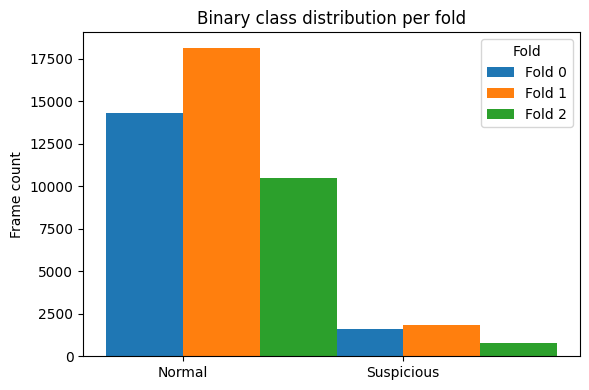

Fold 0: Normal=14304  Suspicious=1598  ratio=9.0:1
Fold 1: Normal=18150  Suspicious=1818  ratio=10.0:1
Fold 2: Normal=10508  Suspicious=783  ratio=13.4:1


In [19]:
label_names = {0: 'Normal', 1: 'Suspicious'}
binary_counts = (
    df.groupby(['binary_label', 'fold'])
    .size()
    .unstack(fill_value=0)
)
binary_counts.index = binary_counts.index.map(label_names)

display(binary_counts)

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(binary_counts))
width = 0.35
for i, fold in enumerate(sorted(df['fold'].unique())):
    ax.bar(x + i * width, binary_counts[fold], width, label=f'Fold {fold}')
ax.set_xticks(x + width / 2)
ax.set_xticklabels(binary_counts.index)
ax.set_title('Binary class distribution per fold')
ax.set_ylabel('Frame count')
ax.legend(title='Fold')
plt.tight_layout()
plt.savefig(EDA_DIR / 'binary_distribution_by_fold.png', dpi=200)
plt.show()

# Imbalance ratio
for fold in sorted(df['fold'].unique()):
    n = binary_counts.loc['Normal', fold]
    s = binary_counts.loc['Suspicious', fold]
    print(f'Fold {fold}: Normal={n}  Suspicious={s}  ratio={n/s:.1f}:1')

eda_summary['binary_counts_by_fold'] = binary_counts.to_dict()

## 3. Intra-video duplication estimate

Unique videos: 43
Total frames: 47161

Frames per video percentiles:
  p 50: 1002
  p 75: 1474
  p 90: 2013
  p 95: 2145
  p 99: 2295
  p100: 2394

Top-10 videos by frame count:
video_id
5e59c7fdb16c4228    2394
64440803f87b4843    2159
dac1e27f7e4d4ef5    2152
fb86bc87d3874cd7    2085
8885668afb844852    2021
131368cc17e44240    1979
bc84479c66fe4da6    1891
dc221ccc65d34010    1789
3c8d5f0b90d7475d    1704
df6b47bafe5143f5    1530


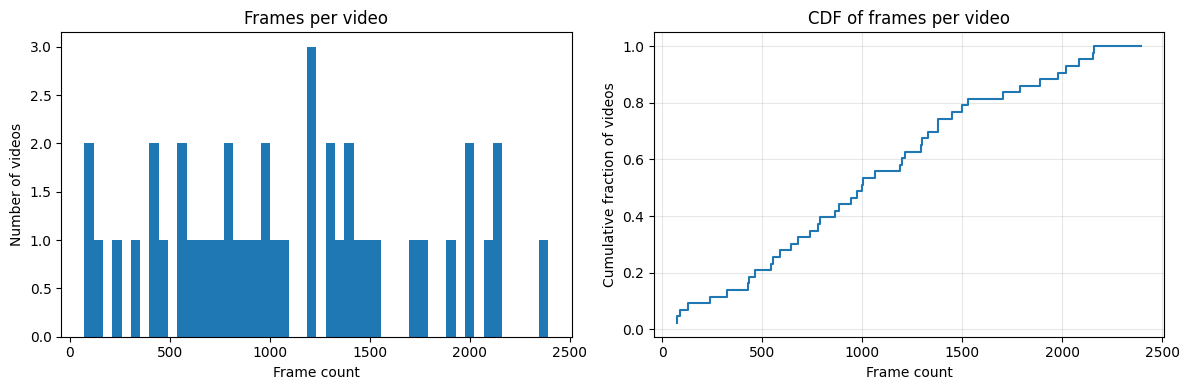

In [6]:
if 'stem' not in df.columns:
    df['stem'] = df['filename'].apply(lambda f: Path(f).stem)

df['video_id'] = df['stem'].apply(infer_video_id)

frames_per_video = df.groupby('video_id').size()

print(f'Unique videos: {len(frames_per_video)}')
print(f'Total frames: {frames_per_video.sum()}')
print(f'\nFrames per video percentiles:')
for p in [50, 75, 90, 95, 99, 100]:
    print(f'  p{p:3d}: {np.percentile(frames_per_video, p):.0f}')

top10 = frames_per_video.nlargest(10)
print(f'\nTop-10 videos by frame count:')
print(top10.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(frames_per_video, bins=50)
axes[0].set_title('Frames per video')
axes[0].set_xlabel('Frame count')
axes[0].set_ylabel('Number of videos')

# CDF
sorted_counts = np.sort(frames_per_video)
cdf = np.arange(1, len(sorted_counts) + 1) / len(sorted_counts)
axes[1].step(sorted_counts, cdf)
axes[1].set_title('CDF of frames per video')
axes[1].set_xlabel('Frame count')
axes[1].set_ylabel('Cumulative fraction of videos')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / 'frames_per_video.png', dpi=200)
plt.show()

eda_summary['intra_video_duplication'] = {
    'n_videos': int(len(frames_per_video)),
    'n_frames': int(frames_per_video.sum()),
    'median_frames_per_video': float(np.median(frames_per_video)),
    'p90_frames_per_video': float(np.percentile(frames_per_video, 90)),
    'p99_frames_per_video': float(np.percentile(frames_per_video, 99)),
    'max_frames_per_video': int(frames_per_video.max()),
    'top10_videos': top10.to_dict(),
}

## 4. Exclusion impact summary

In [ ]:
# Compute exclusion impact dynamically from labelled_images/ and EXCLUDED_CLASSES
_labelled_dir = PROJECT_ROOT / 'data' / 'labelled_images'

if not _labelled_dir.exists():
    _preproc_cfg_path = preprocessed_root() / 'preprocessing_config.json'
    with open(_preproc_cfg_path) as _f:
        _excluded_cls_list = json.load(_f)['excluded_classes']
    excluded_counts = {cls: None for cls in sorted(_excluded_cls_list)}
    print(f'labelled_images/ not found at {_labelled_dir}.')
    print('Counts unavailable; class list from preprocessing_config.json:')
else:
    excluded_counts = {}
    for _cls_dir in sorted(_labelled_dir.iterdir()):
        if not _cls_dir.is_dir():
            continue
        _subclass = DIR_NAME_MAP.get(_cls_dir.name, _cls_dir.name)
        if _subclass in EXCLUDED_CLASSES:
            excluded_counts[_subclass] = sum(1 for _ in _cls_dir.rglob('*.jpg'))

print("Excluded classes:")
for cls, n in sorted(excluded_counts.items()):
    print(f"  {cls}: {n if n is not None else 'N/A'} images")

total_active = len(df)
total_excluded = sum(v for v in excluded_counts.values() if v is not None)
total_in_dataset = total_active + total_excluded

print(f"\nSummary:")
print(f"  Total images in labelled_images: {total_in_dataset}")
print(f"  Excluded ({len(excluded_counts)} classes): {total_excluded}")
print(f"  Active in manifest: {total_active}")

eda_summary["exclusion_impact"] = {
    "excluded_classes": {k: v for k, v in excluded_counts.items() if v is not None},
    "total_excluded": total_excluded,
    "total_active": total_active,
}

## 5. Bounding-box normalized area distribution

BBox entries: 4115
p10=0.0173  median=0.0463  p90=0.3509
First-block downsampling should be removed: True


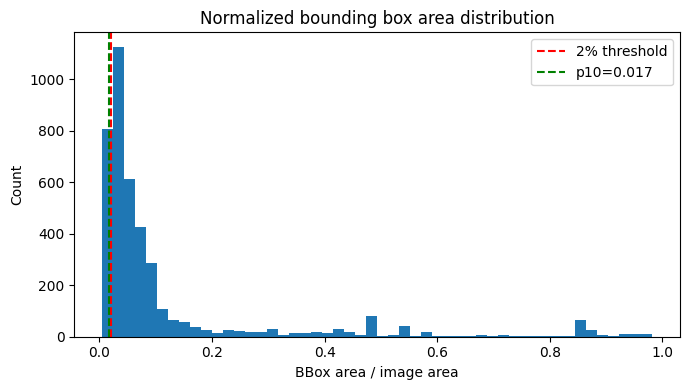

In [8]:
if 'bbox_norm_area' in df.columns:
    areas = df['bbox_norm_area'].dropna().to_numpy(dtype=float)
    areas = areas[(areas >= 0) & (areas <= 1)]
else:
    areas = np.array([])

if len(areas) == 0:
    print('No bounding box data in manifest. Skipping bbox analysis.')
    eda_summary['bbox_area'] = None
else:
    p10, p50, p90 = float(np.percentile(areas, 10)), float(np.percentile(areas, 50)), float(np.percentile(areas, 90))
    print(f'BBox entries: {len(areas)}')
    print(f'p10={p10:.4f}  median={p50:.4f}  p90={p90:.4f}')
    print('First-block downsampling should be removed:', p10 < 0.02)

    plt.figure(figsize=(7, 4))
    plt.hist(areas, bins=50)
    plt.axvline(0.02, linestyle='--', color='r', label='2% threshold')
    plt.axvline(p10, linestyle='--', color='g', label=f'p10={p10:.3f}')
    plt.title('Normalized bounding box area distribution')
    plt.xlabel('BBox area / image area')
    plt.ylabel('Count')
    plt.legend()
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'bbox_area_distribution.png', dpi=200)
    plt.show()

    eda_summary['bbox_area'] = {
        'n': int(len(areas)),
        'p10': p10,
        'median': p50,
        'p90': p90,
        'first_block_downsampling_should_be_removed': bool(p10 < 0.02),
    }

## 6. Preprocessing verification, images from NPZ shards

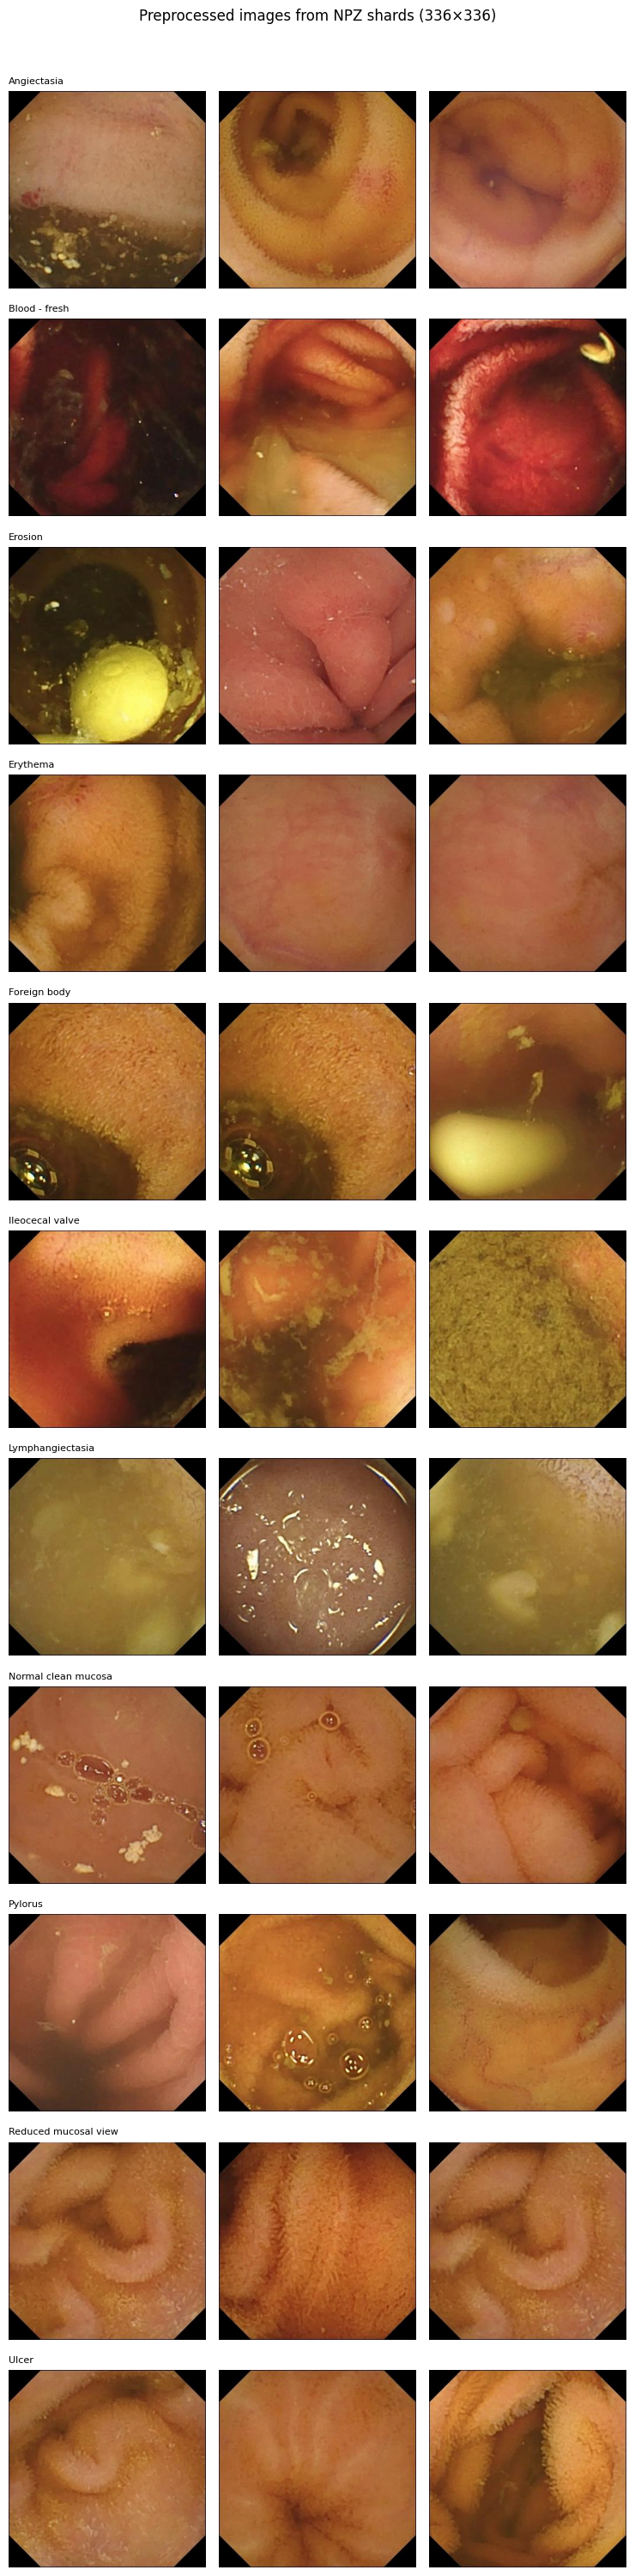

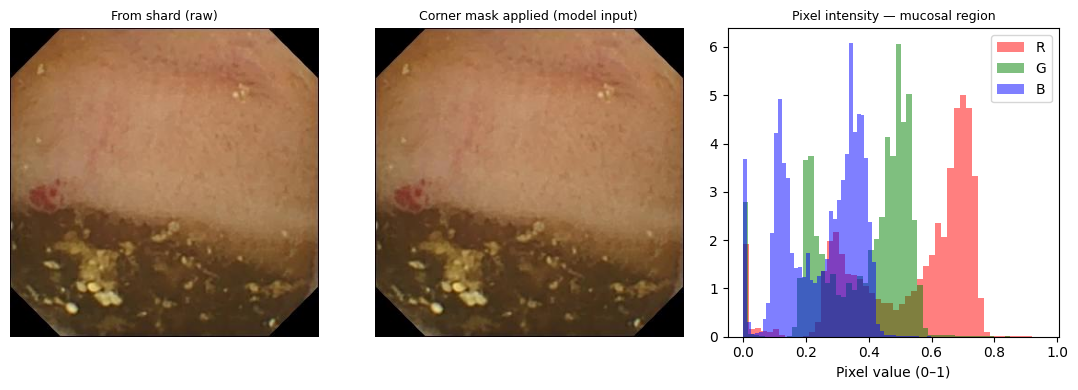

Image shape: (336, 336, 3)  dtype: uint8
Mucosal pixels: 111437 / 112896 (98.7%)


In [9]:
N_PER_CLASS_SAMPLE = 3
rng_pp = np.random.default_rng(7)

preproc_items = []
for subclass in sorted(df['subclass'].unique()):
    sub_df = df[df['subclass'] == subclass]
    idxs = rng_pp.choice(sub_df.index.to_numpy(),
                         size=min(N_PER_CLASS_SAMPLE, len(sub_df)),
                         replace=False)
    for idx in idxs:
        img = load_image_from_row(sub_df.loc[idx])
        if img is not None:
            preproc_items.append((subclass, img))

if not preproc_items:
    print('Shards not accessible, preprocessing verification skipped.')
else:
    unique_cls = list(dict.fromkeys(r[0] for r in preproc_items))
    n_r, n_c = len(unique_cls), N_PER_CLASS_SAMPLE
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.5 * n_c, 2.7 * n_r))
    if n_r == 1:
        axes = axes[np.newaxis, :]

    for i, cls in enumerate(unique_cls):
        cls_imgs = [r[1] for r in preproc_items if r[0] == cls]
        for j in range(n_c):
            axes[i, j].axis('off')
            if j < len(cls_imgs):
                axes[i, j].imshow(cls_imgs[j])
                if j == 0:
                    axes[i, j].set_title(cls, fontsize=8, loc='left')

    plt.suptitle('Preprocessed images from NPZ shards (336×336)', y=1.01)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'preprocessed_sample_grid.png', dpi=200, bbox_inches='tight')
    plt.show()

    # Corner mask check: one image raw, one with mask applied, pixel histogram
    mask_path = corner_mask_path()
    img0 = preproc_items[0][1]
    if mask_path.exists():
        cmask = np.load(str(mask_path))
        masked = img0.copy()
        masked[~cmask] = 0

        fig, axes2 = plt.subplots(1, 3, figsize=(11, 4))
        axes2[0].imshow(img0)
        axes2[0].set_title('From shard (raw)', fontsize=9)
        axes2[0].axis('off')

        axes2[1].imshow(masked)
        axes2[1].set_title('Corner mask applied (model input)', fontsize=9)
        axes2[1].axis('off')

        for ch, color in enumerate(('r', 'g', 'b')):
            vals = img0[:, :, ch][cmask].ravel() / 255.
            axes2[2].hist(vals, bins=50, alpha=0.5, color=color,
                          label='RGB'[ch], density=True)
        axes2[2].set_title('Pixel intensity — mucosal region', fontsize=9)
        axes2[2].set_xlabel('Pixel value (0–1)')
        axes2[2].legend()
        plt.tight_layout()
        plt.savefig(EDA_DIR / 'preprocessing_corner_mask_check.png', dpi=200)
        plt.show()
        print(f'Image shape: {img0.shape}  dtype: {img0.dtype}')
        print(f'Mucosal pixels: {cmask.sum()} / {cmask.size} ({100*cmask.mean():.1f}%)')
    else:
        print(f'Corner mask not found at {mask_path}. Run preprocess.py first.')


## 7. Visual ambiguity grid

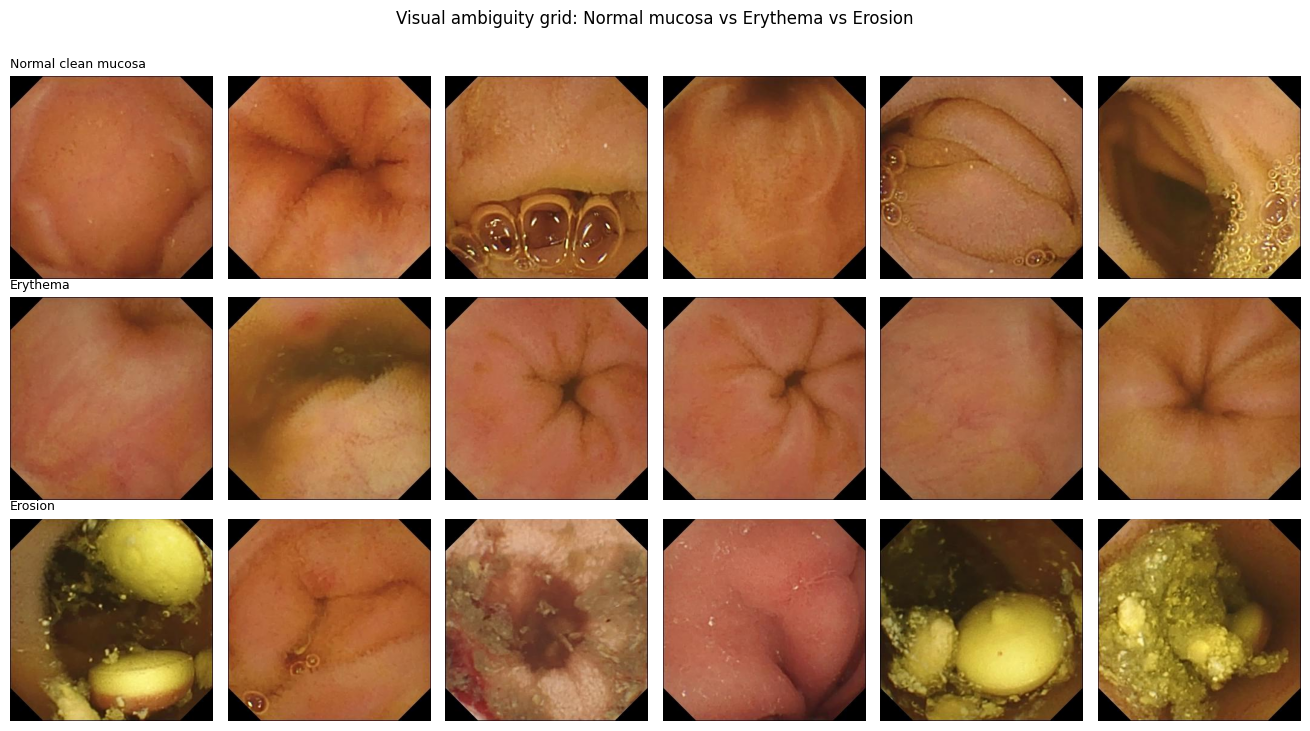

In [10]:
TARGET_SUBCLASSES = ('Normal clean mucosa', 'Erythema', 'Erosion')
N_PER_CLASS = 6
rng = np.random.default_rng(42)

grid_rows = []
for subclass in TARGET_SUBCLASSES:
    sub_df = df[df['subclass'] == subclass]
    if sub_df.empty:
        warnings.warn(f'No samples for subclass: {subclass}')
        continue
    sample_idx = rng.choice(sub_df.index.to_numpy(), size=min(N_PER_CLASS, len(sub_df)), replace=False)
    for idx in sample_idx:
        img = load_image_from_row(sub_df.loc[idx])
        if img is not None:
            grid_rows.append((subclass, img))

if grid_rows:
    unique_classes = list(dict.fromkeys(r[0] for r in grid_rows))
    n_r, n_c = len(unique_classes), N_PER_CLASS
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.2 * n_c, 2.4 * n_r))
    if n_r == 1:
        axes = axes[np.newaxis, :]
    for i, cls in enumerate(unique_classes):
        cls_imgs = [r[1] for r in grid_rows if r[0] == cls]
        for j in range(n_c):
            axes[i, j].axis('off')
            if j < len(cls_imgs):
                axes[i, j].imshow(cls_imgs[j])
                if j == 0:
                    axes[i, j].set_title(cls, fontsize=9, loc='left')
    plt.suptitle('Visual ambiguity grid: Normal mucosa vs Erythema vs Erosion', y=1.01)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'visual_ambiguity_grid.png', dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('Shards not accessible from this machine, ambiguity grid skipped.')

## 8. Per-fold normalization statistics

Normalization stats from: D:\Git\AAIB\outputs\preprocessed\normalization_stats.json
  all       mean=[0.6023, 0.3690, 0.1858]  std=[0.1831, 0.1355, 0.0913]
  fold_0    mean=[0.6037, 0.3650, 0.1840]  std=[0.1890, 0.1381, 0.0911]
  fold_1    mean=[0.6012, 0.3722, 0.1873]  std=[0.1781, 0.1332, 0.0915]


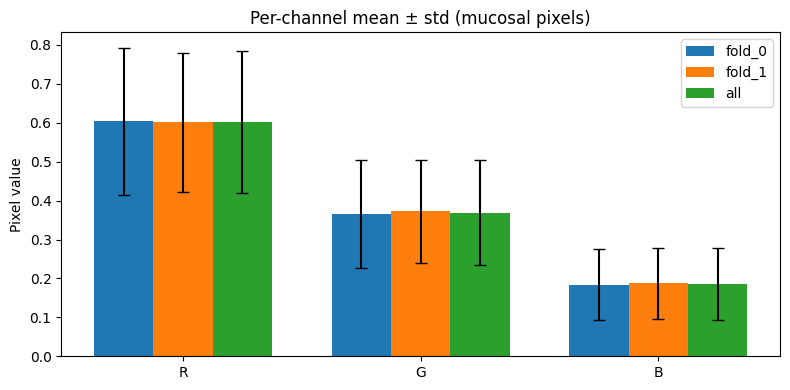

In [11]:
norm_path = norm_stats_path()
if not norm_path.exists():
    norm_path = outputs_root().parent / 'outputs_phase1_2_3' / 'normalization_stats.json'

if norm_path.exists():
    with open(norm_path) as f:
        norm_stats = json.load(f)

    print(f'Normalization stats from: {norm_path}')
    for scope in ('all', 'fold_0', 'fold_1'):
        if scope not in norm_stats:
            continue
        s = norm_stats[scope]
        mean = s['mean']
        std = s['std']
        print(f'  {scope:8s}  mean=[{mean[0]:.4f}, {mean[1]:.4f}, {mean[2]:.4f}]  '
              f'std=[{std[0]:.4f}, {std[1]:.4f}, {std[2]:.4f}]')

    # Bar chart of per-channel mean/std
    scopes = [s for s in ('fold_0', 'fold_1', 'all') if s in norm_stats]
    channels = ['R', 'G', 'B']
    x = np.arange(3)
    width = 0.25
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, scope in enumerate(scopes):
        means = norm_stats[scope]['mean']
        stds = norm_stats[scope]['std']
        ax.bar(x + i * width, means, width, yerr=stds, capsize=4, label=scope)
    ax.set_xticks(x + width)
    ax.set_xticklabels(channels)
    ax.set_title('Per-channel mean ± std (mucosal pixels)')
    ax.set_ylabel('Pixel value')
    ax.legend()
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'normalization_stats.png', dpi=200)
    plt.show()

    eda_summary['normalization_stats'] = {
        k: v for k, v in norm_stats.items() if k != 'note'
    }
else:
    print(f'normalization_stats.json not found at {norm_path}.')
    print('Run scripts/preprocess.py without --no-norm-stats first.')

## 9. Bounding-box position verification

Annotated bbox frames: 4235
Finding classes: ['Ampulla of Vater', 'Angiectasia', 'Blood - fresh', 'Blood - hematin', 'Erosion', 'Erythema', 'Foreign Body', 'Lymphangiectasia', 'Polyp', 'Ulcer']
Bbox frames with shard info: 4167


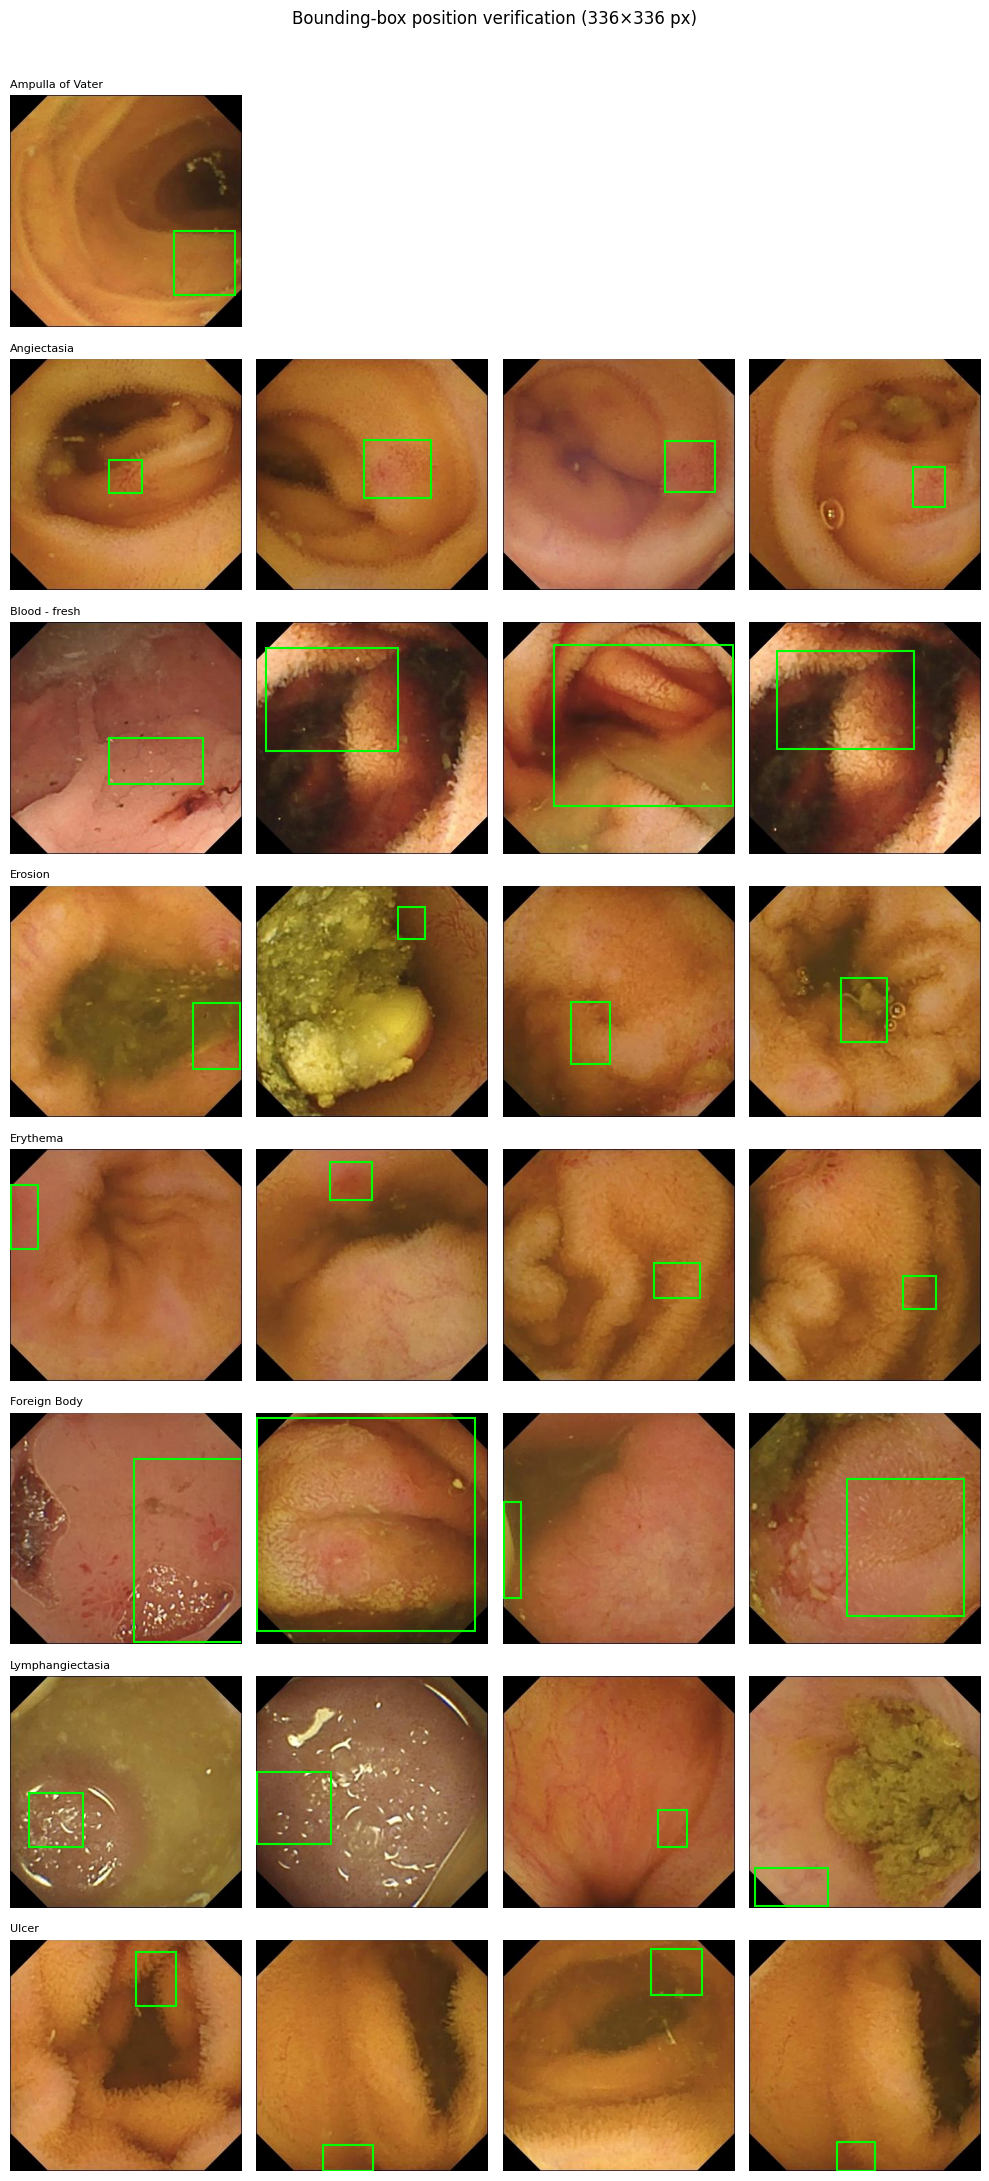

In [12]:
METADATA_CSV = PROJECT_ROOT / 'data' / 'metadata.csv'

if not METADATA_CSV.exists():
    print(f'metadata.csv not found at {METADATA_CSV}. Skipping bbox verification.')
else:
    meta = pd.read_csv(METADATA_CSV, sep=';')
    meta['stem'] = meta['filename'].apply(lambda f: Path(f).stem)

    # Only rows with bbox annotations (non-empty x1)
    bbox_meta = meta[meta['x1'].notna()].copy()
    for col in ('x1', 'y1', 'x2', 'y2', 'x3', 'y3', 'x4', 'y4'):
        bbox_meta[col] = bbox_meta[col].astype(float)

    print(f'Annotated bbox frames: {len(bbox_meta)}')
    print(f'Finding classes: {sorted(bbox_meta["finding_class"].unique())}')

    # Join with manifest to get shard columns for load_image_from_row
    shard_cols = [c for c in ('shard_rel_path', 'shard_path') if c in df.columns]
    manifest_sub = df[['stem', 'local_idx'] + shard_cols].copy()
    merged = bbox_meta.merge(manifest_sub, on='stem', how='inner')
    print(f'Bbox frames with shard info: {len(merged)}')

    N_PER_CLASS_BBOX = 4
    TARGET_BBOX_CLASSES = sorted(merged['finding_class'].unique())

    grid_items = []
    for cls in TARGET_BBOX_CLASSES:
        cls_df = merged[merged['finding_class'] == cls]
        sample = cls_df.sample(min(N_PER_CLASS_BBOX, len(cls_df)), random_state=0)
        for _, row in sample.iterrows():
            img = load_image_from_row(row)
            if img is not None:
                pts = np.array([
                    [row['x1'], row['y1']],
                    [row['x2'], row['y2']],
                    [row['x3'], row['y3']],
                    [row['x4'], row['y4']],
                ])
                grid_items.append((cls, img, pts))

    if not grid_items:
        print('Shards not accessible from this machine — bbox verification grid skipped.')
    else:
        unique_cls = list(dict.fromkeys(r[0] for r in grid_items))
        n_r = len(unique_cls)
        n_c = N_PER_CLASS_BBOX
        fig, axes = plt.subplots(n_r, n_c, figsize=(2.5 * n_c, 2.7 * n_r))
        if n_r == 1:
            axes = axes[np.newaxis, :]

        for i, cls in enumerate(unique_cls):
            cls_items = [(img, pts) for (c, img, pts) in grid_items if c == cls]
            for j in range(n_c):
                axes[i, j].axis('off')
                if j < len(cls_items):
                    img, pts = cls_items[j]
                    axes[i, j].imshow(img)
                    poly = plt.Polygon(pts, closed=True, fill=False,
                                       edgecolor='lime', linewidth=1.5)
                    axes[i, j].add_patch(poly)
                    if j == 0:
                        axes[i, j].set_title(cls, fontsize=8, loc='left')

        plt.suptitle('Bounding-box position verification (336×336 px)', y=1.01)
        plt.tight_layout()
        plt.savefig(EDA_DIR / 'bbox_position_verification.png', dpi=200, bbox_inches='tight')
        plt.show()


## 10. Augmented dataset visualizations

Shows the training augmentation pipeline (horizontal/vertical flip, ±360° rotation, colour jitter, Gaussian blur — defined in `src/kvasir_triage/data/transforms.py`) applied to representative images.

- **Sample grid**: one row per subclass, original followed by 5 independently-sampled augmented variants.
- **Per-transform breakdown**: 4 representative images with each transform applied in isolation at p=1, so the effect of each operation is unambiguous.

In [ ]:
import albumentations as A

# Visual-only augmentation pipeline (Normalize/ToTensorV2 omitted so images stay displayable)
# Matches src/kvasir_triage/data/transforms.py::build_train_transform
_visual_aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=360, border_mode=0, p=0.7),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.0, p=0.5),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
])

N_AUG_VARIANTS = 5
rng_aug = np.random.default_rng(99)

aug_items = []
for subclass in sorted(df['subclass'].unique()):
    sub_df = df[df['subclass'] == subclass]
    idx = rng_aug.choice(sub_df.index.to_numpy())
    orig = load_image_from_row(sub_df.loc[idx])
    if orig is None:
        continue
    variants = [_visual_aug(image=orig)['image'] for _ in range(N_AUG_VARIANTS)]
    aug_items.append((subclass, orig, variants))

if not aug_items:
    print('Shards not accessible — augmentation sample grid skipped.')
else:
    n_r = len(aug_items)
    n_c = 1 + N_AUG_VARIANTS
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.5 * n_c, 2.7 * n_r))
    if n_r == 1:
        axes = axes[np.newaxis, :]

    for i, (cls, orig, variants) in enumerate(aug_items):
        for j, img in enumerate([orig] + variants):
            ax = axes[i, j]
            ax.imshow(img)
            ax.axis('off')
            if i == 0:
                ax.set_title('Original' if j == 0 else f'Aug {j}', fontsize=8)
            if j == 0:
                ax.set_ylabel(cls, fontsize=7, rotation=0, ha='right', va='center', labelpad=55)

    plt.suptitle('Training augmentations: original + 5 random variants per subclass', y=1.01)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'augmentation_sample_grid.png', dpi=200, bbox_inches='tight')
    plt.show()
    print(f'Saved: {EDA_DIR / "augmentation_sample_grid.png"}')


In [ ]:
import albumentations as A

# Per-augmentation breakdown: each transform applied in isolation at p=1
# Mirrors the pipeline in src/kvasir_triage/data/transforms.py::build_train_transform
_TRANSFORMS_ISOLATED = [
    ('HFlip',        A.HorizontalFlip(p=1)),
    ('VFlip',        A.VerticalFlip(p=1)),
    ('Rotate ±360°', A.Rotate(limit=360, border_mode=0, p=1)),
    ('ColorJitter',  A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.0, p=1)),
    ('GaussianBlur', A.GaussianBlur(blur_limit=(3, 5), p=1)),
]

_DEMO_SUBCLASSES = ['Normal clean mucosa', 'Erosion', 'Angiectasia', 'Erythema']
rng_iso = np.random.default_rng(7)
demo_imgs = []
for _sc in _DEMO_SUBCLASSES:
    _sub = df[df['subclass'] == _sc]
    if _sub.empty:
        continue
    _img = load_image_from_row(_sub.loc[rng_iso.choice(_sub.index.to_numpy())])
    if _img is not None:
        demo_imgs.append((_sc, _img))

if not demo_imgs:
    print('Shards not accessible — augmentation breakdown skipped.')
else:
    n_r = len(demo_imgs)
    n_c = 1 + len(_TRANSFORMS_ISOLATED)
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.5 * n_c, 2.7 * n_r))
    if n_r == 1:
        axes = axes[np.newaxis, :]

    for j, title in enumerate(['Original'] + [t[0] for t in _TRANSFORMS_ISOLATED]):
        axes[0, j].set_title(title, fontsize=8)

    for i, (sc, orig) in enumerate(demo_imgs):
        axes[i, 0].imshow(orig)
        axes[i, 0].axis('off')
        axes[i, 0].set_ylabel(sc, fontsize=7, rotation=0, ha='right', va='center', labelpad=55)
        for j, (_, tf) in enumerate(_TRANSFORMS_ISOLATED):
            axes[i, j + 1].imshow(tf(image=orig.copy())['image'])
            axes[i, j + 1].axis('off')

    plt.suptitle('Per-augmentation breakdown (each transform at p=1)', y=1.01)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'augmentation_breakdown.png', dpi=200, bbox_inches='tight')
    plt.show()
    print(f'Saved: {EDA_DIR / "augmentation_breakdown.png"}')


In [13]:
# Save EDA summary
eda_summary_path = EDA_DIR / 'eda_summary.json'
with open(eda_summary_path, 'w') as f:
    json.dump(eda_summary, f, indent=2, default=str)

print(f'EDA summary written to {eda_summary_path}')
print(f'Plots saved to {EDA_DIR}')

EDA summary written to D:\Git\AAIB\outputs\eda\eda_summary.json
Plots saved to D:\Git\AAIB\outputs\eda
